# 02 - Features, models and evaluation

**Goal:** rank the at-risk households by churn risk, so a limited coupon budget goes to those most likely to stop shopping.
Code: `src/features.py` (labels + features), `src/train.py` (split, preprocessing, models, evaluation).

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the repo root whether the notebook is opened from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Snapshots and the time-based split

**Question:** how do we turn 102 weeks of purchases into training rows without letting the model see the future?

For each **snapshot** week *c* (30, 38, ..., 94) we take the households at risk at *c*, compute features from **weeks <= c only**,
and the label from weeks *c+1 .. c+8*. Stacking the 9 snapshots gives more training rows.

In [2]:
from src.features import BEHAVIOUR_FEATURES, FEATURES, build_model_table, load_inputs

table = build_model_table(*load_inputs())
print(f"{len(table):,} rows, {table['household_key'].nunique():,} households, overall churn rate {table['churn'].mean():.1%}")
print(f"the model uses {len(FEATURES)} behaviour features (demographics are only used in section 6)")
table.groupby("cutoff_week")["churn"].agg(households="size", churn_rate="mean")

20,588 rows, 2,485 households, overall churn rate 7.2%
the model uses 12 behaviour features (demographics are only used in section 6)


,households,churn_rate
cutoff_week,,
30,2288,0.080
38,2275,0.076
46,2258,0.072
54,2267,0.065
62,2280,0.068
70,2306,0.074
78,2302,0.066
86,2296,0.068
94,2316,0.082


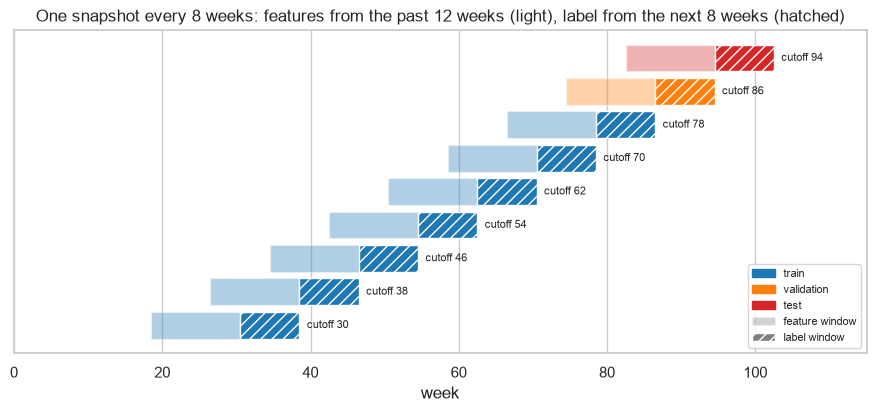

In [3]:
from matplotlib.patches import Patch
from src.config import OBSERVATION_WEEKS, PREDICTION_WEEKS, TEST_CUTOFF, VALID_CUTOFF

colors = {"train": "tab:blue", "validation": "tab:orange", "test": "tab:red"}
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, c in enumerate(sorted(table["cutoff_week"].unique())):
    role = "test" if c == TEST_CUTOFF else "validation" if c == VALID_CUTOFF else "train"
    ax.barh(i, OBSERVATION_WEEKS, left=c - OBSERVATION_WEEKS + 0.5, color=colors[role], alpha=0.35)   # features
    ax.barh(i, PREDICTION_WEEKS, left=c + 0.5, color=colors[role], hatch="///", edgecolor="white")    # label
    ax.text(c + PREDICTION_WEEKS + 1.5, i, f"cutoff {c}", va="center", fontsize=8)
ax.set(yticks=[], xlim=(0, 115), xlabel="week",
       title="One snapshot every 8 weeks: features from the past 12 weeks (light), label from the next 8 weeks (hatched)")
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items()]
          + [Patch(facecolor="grey", alpha=0.35, label="feature window"), Patch(facecolor="grey", hatch="///", label="label window")],
          loc="lower right", fontsize=8)
fig.savefig(FIGURES_DIR / "snapshot_timeline.png", dpi=120, bbox_inches="tight")
plt.show()

**So what:** train = snapshots 30 ... 78, **validation** = 86 (choose the settings), **test** = 94 (used once, at the end).
A label window is 8 weeks long and snapshots are 8 weeks apart, so the label windows never overlap: no model learns from weeks
it is later asked to predict (`time_split` checks this, and a unit test checks `time_split`).

## 2. Do the features separate churners from non-churners?

**Question:** before any model, do churners and non-churners behave differently?

In [4]:
table.groupby("churn")[BEHAVIOUR_FEATURES].median().T

churn,0,1
recency_weeks,0.000,3.000
tenure_weeks,53.000,54.000
active_share,0.607,0.242
active_weeks_4w,3.000,1.000
active_weeks_12w,8.000,2.000
baskets_12w,11.000,2.000
sales_12w,322.395,55.695
avg_basket_value_12w,26.748,19.348
trend_4w_vs_12w,0.000,-0.083
discount_share_12w,0.147,0.133


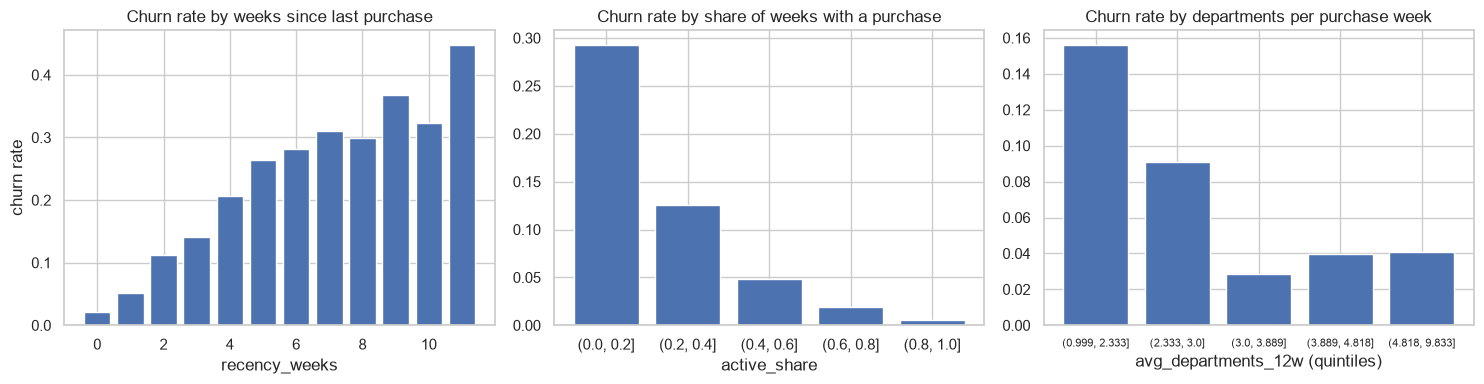

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

by_recency = table.groupby("recency_weeks")["churn"].mean()
axes[0].bar(by_recency.index, by_recency.values)
axes[0].set(title="Churn rate by weeks since last purchase", xlabel="recency_weeks", ylabel="churn rate")

share_bin = pd.cut(table["active_share"], [0, 0.2, 0.4, 0.6, 0.8, 1.0])
by_share = table.groupby(share_bin, observed=True)["churn"].mean()
axes[1].bar(by_share.index.astype(str), by_share.values)
axes[1].set(title="Churn rate by share of weeks with a purchase", xlabel="active_share")

dept_bin = pd.qcut(table["avg_departments_12w"], 5, duplicates="drop")
by_dept = table.groupby(dept_bin, observed=True)["churn"].mean()
axes[2].bar(by_dept.index.astype(str), by_dept.values)
axes[2].set(title="Churn rate by departments per purchase week", xlabel="avg_departments_12w (quintiles)")
axes[2].tick_params(axis="x", labelsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "churn_rate_by_feature.png", dpi=120, bbox_inches="tight")
plt.show()

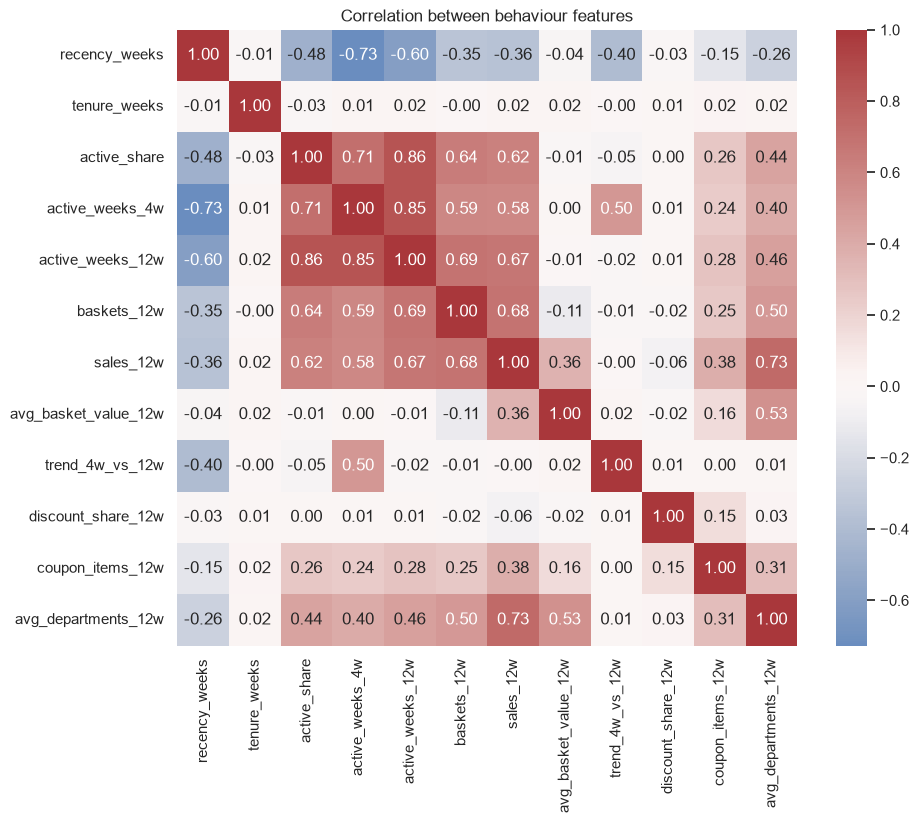

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(table[BEHAVIOUR_FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation between behaviour features")
plt.show()

In [7]:
table.groupby(table["has_demographics"].map({0: "no demographics", 1: "has demographics"}))["churn"].agg(["size", "mean"])

,size,mean
has_demographics,,
has demographics,7132,0.010
no demographics,13456,0.106


**So what:**
* Churn rises clearly with recency and falls with how regularly a household shops, and with how many departments it buys from
  (households that do only a small part of their shopping here are easier to lose).
* Some features are strongly correlated (e.g. `active_weeks_12w` and `baskets_12w`): fine for ranking, but the logistic
  coefficients of correlated features must be read together (notebook 03).
* **Warning sign:** households *with* demographics almost never churn (~1% vs ~11%). The survey was probably answered by
  loyal households, so "has demographics" may partly encode the future. Section 6 tests whether the model needs demographics.

## 3. Preprocessing pipeline

**Question:** how do we put the features on one scale without using information from the validation or test weeks?

One `ColumnTransformer` inside each model's `Pipeline`, so it is **fitted on the training weeks only**:

| Columns | Steps |
|---|---|
| skewed counts and amounts (`sales_12w`, `baskets_12w`, `avg_basket_value_12w`, `coupon_items_12w`) | `log1p` -> standardize |
| the other 8 behaviour features | standardize |

The behaviour features have no missing values (no purchase in a window = 0), so nothing needs to be filled.

In [8]:
from src.train import make_preprocessor, time_split

train, valid, test = time_split(table)
print(f"train {len(train):,} rows | validation {len(valid):,} rows | test {len(test):,} rows")
prep = make_preprocessor().fit(train[FEATURES])
X_train = pd.DataFrame(prep.transform(train[FEATURES]), columns=prep.get_feature_names_out())
X_train.describe().T[["mean", "std", "min", "max"]]

train 15,976 rows | validation 2,296 rows | test 2,316 rows


,mean,std,min,max
baskets_12w,3.327e-16,1.0,-1.876,3.397
sales_12w,1.566e-16,1.0,-3.933,2.495
avg_basket_value_12w,-2.322e-16,1.0,-4.193,3.360
coupon_items_12w,-4.270e-17,1.0,-0.620,5.032
recency_weeks,5.960e-17,1.0,-0.572,4.292
tenure_weeks,-5.693e-17,1.0,-2.619,1.963
active_share,-8.006e-17,1.0,-2.016,1.593
active_weeks_4w,7.294e-17,1.0,-1.668,1.213
active_weeks_12w,-3.024e-17,1.0,-1.649,1.411
trend_4w_vs_12w,-7.116e-18,1.0,-3.699,3.681


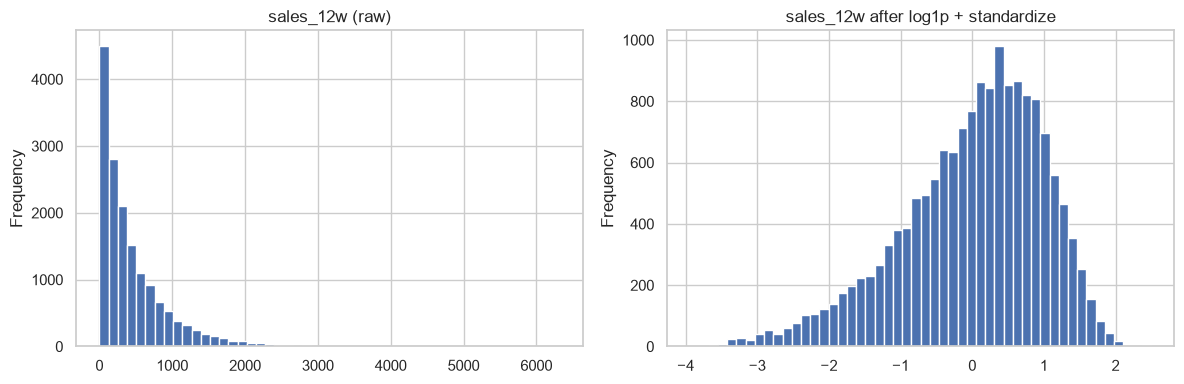

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train["sales_12w"].plot.hist(bins=50, ax=axes[0], title="sales_12w (raw)")
X_train["sales_12w"].plot.hist(bins=50, ax=axes[1], title="sales_12w after log1p + standardize")
fig.tight_layout()
plt.show()

**So what:** every feature now has mean 0 and standard deviation 1 on the training weeks, so the logistic coefficients
(notebook 03) can be compared with each other, and a few very big spenders no longer dominate `sales_12w`.

## 4. Which model? Validation on week 86, test on week 94

**Question:** does machine learning beat a simple rule, and which model should we use?

* Three candidates: the **recency rule** (no ML: longest silence first, ties broken by fewer purchase weeks),
  **logistic regression** (a linear model) and **random forest** (a tree model), each with a small grid of settings.
* Each setting is trained on weeks 30 ... 78 and scored on week 86; the best setting of each model is kept.
* No random k-fold: the same household appears in several snapshots, and in real life we predict the future from the past.
* Churn is rare (~7%), so accuracy is useless (predicting "no churn" for everyone already gives 93%). We use **PR-AUC**, and
  also report **precision in the top 10%** (the coupon budget), **lift** (how many times better than a random 10%) and ROC-AUC.

In [10]:
from src.train import GRIDS, tune

for name, grid in GRIDS.items():
    print(f"{name:14s} {np.prod([len(v) for v in grid.values()])} settings: {grid}")
print()
best = tune(train, valid)
best

logistic       4 settings: {'clf__C': [0.01, 0.1, 1, 10]}
random_forest  9 settings: {'clf__max_depth': [4, 8, 12], 'clf__min_samples_leaf': [20, 50, 100]}

logistic       {'clf__C': 0.01}                                        valid PR-AUC 0.296
logistic       {'clf__C': 0.1}                                         valid PR-AUC 0.296
logistic       {'clf__C': 1}                                           valid PR-AUC 0.296


logistic       {'clf__C': 10}                                          valid PR-AUC 0.296


random_forest  {'clf__max_depth': 4, 'clf__min_samples_leaf': 20}      valid PR-AUC 0.315


random_forest  {'clf__max_depth': 4, 'clf__min_samples_leaf': 50}      valid PR-AUC 0.317


random_forest  {'clf__max_depth': 4, 'clf__min_samples_leaf': 100}     valid PR-AUC 0.308


...

random_forest  {'clf__max_depth': 8, 'clf__min_samples_leaf': 100}     valid PR-AUC 0.318


random_forest  {'clf__max_depth': 12, 'clf__min_samples_leaf': 20}     valid PR-AUC 0.321


random_forest  {'clf__max_depth': 12, 'clf__min_samples_leaf': 50}     valid PR-AUC 0.322


random_forest  {'clf__max_depth': 12, 'clf__min_samples_leaf': 100}    valid PR-AUC 0.316


,params,valid_pr_auc
model,,
recency_rule,{},0.256
logistic,{'clf__C': 0.1},0.296
random_forest,"{'clf__max_depth': 12, 'clf__min_samples_leaf'...",0.322


On validation both ML models beat the rule. The forest scores a bit higher, but it is also the best of 9 settings
(the more settings we try, the more one of them looks good by luck), while logistic regression gives the same score for every `C`.
Next, each best setting is refit on every week before the test (train + validation) and scored **once** on week 94.

In [11]:
from src.train import evaluate, score_with_best

test_scores = score_with_best(best, pd.concat([train, valid]), test)
test_results = pd.DataFrame({name: evaluate(test["churn"], test_scores[f"score_{name}"]) for name in best.index}).T
test_results

,roc_auc,pr_auc,precision_top10,lift_top10
recency_rule,0.816,0.265,0.320,3.926
logistic,0.857,0.326,0.355,4.350
random_forest,0.855,0.330,0.359,4.403


### Is the difference real? Bootstrap intervals

One week has only ~150-190 churners, so every metric is noisy. We resample the households of the week 1,000 times
with replacement and recompute the PR-AUC each time: the middle 95% of these values is the interval (`src/experiments.py`).

In [12]:
from sklearn.metrics import average_precision_score
from src.experiments import bootstrap_ci

valid_scores = score_with_best(best, train, valid)          # the same fits as in tune
rows = []
for week, scores in [("validation (86)", valid_scores), ("test (94)", test_scores)]:
    for name in best.index:
        y, s = scores["churn"], scores[f"score_{name}"]
        low, high = bootstrap_ci(y, s)
        rows.append({"week": week, "model": name, "pr_auc": average_precision_score(y, s), "ci_low": low, "ci_high": high})
boot = pd.DataFrame(rows).set_index(["week", "model"])
boot

pr_auc  ci_low  ci_high
week            model                                 
validation (86) recency_rule    0.256   0.206    0.325
                logistic        0.296   0.243    0.372
                random_forest   0.322   0.264    0.402
test (94)       recency_rule    0.265   0.214    0.319
                logistic        0.326   0.270    0.393
                random_forest   0.330   0.273    0.400

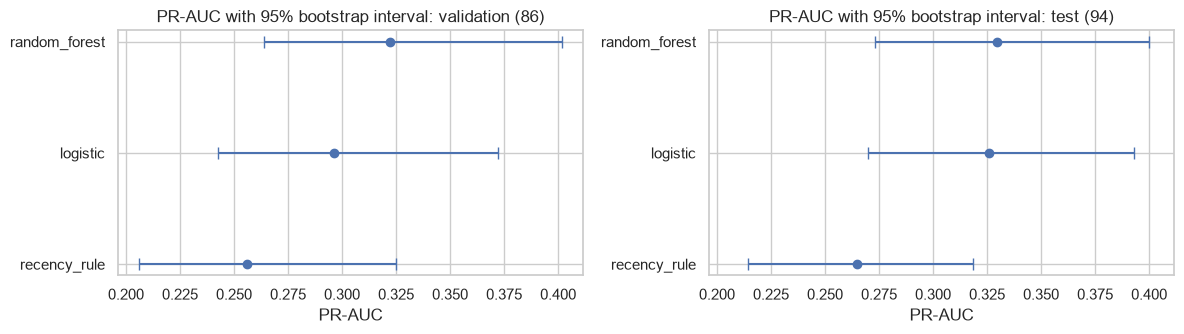

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for ax, week in zip(axes, ["validation (86)", "test (94)"]):
    b = boot.loc[week]
    ax.errorbar(b["pr_auc"], b.index, xerr=[b["pr_auc"] - b["ci_low"], b["ci_high"] - b["pr_auc"]], fmt="o", capsize=4)
    ax.set(title=f"PR-AUC with 95% bootstrap interval: {week}", xlabel="PR-AUC")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "bootstrap_intervals.png", dpi=120, bbox_inches="tight")
plt.show()

**So what:** both ML models beat the recency rule (about +0.06 PR-AUC on test). Logistic regression and random forest are within
0.004 of each other on test, and their intervals overlap on both weeks, so we cannot claim that one is better.

## 5. Do demographics help?

**Question:** households with demographics almost never churn (section 2). Is that a useful signal, or a bias to keep out of the model?

Same models and settings, trained on weeks 30 ... 78 without and with the 5 demographic columns, scored on week 86.
For the demographics: median filling + standardizing for the numbers, an "unknown" category + one-hot for the text columns.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.features import CATEGORICAL_DEMOGRAPHICS, NUMERIC_DEMOGRAPHICS
from src.train import build_model

DEMOGRAPHICS = NUMERIC_DEMOGRAPHICS + CATEGORICAL_DEMOGRAPHICS

def with_demographics(name, params):
    """The same model, with the demographic columns added to the preprocessing."""
    prep = ColumnTransformer([
        ("behaviour", make_preprocessor(), FEATURES),
        ("numeric_demo", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_DEMOGRAPHICS),
        ("categorical_demo", make_pipeline(SimpleImputer(strategy="constant", fill_value="unknown"),
                                           OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CATEGORICAL_DEMOGRAPHICS),
    ])
    return Pipeline([("prep", prep), ("clf", build_model(name, params)[-1])])

In [15]:
from src.train import validation_score

ablation = {}
for name in ["logistic", "random_forest"]:
    params = best.loc[name, "params"]
    model = with_demographics(name, params).fit(train[FEATURES + DEMOGRAPHICS], train["churn"])
    ablation[name] = {
        "without demographics": validation_score(build_model(name, params), train, valid),
        "with demographics": average_precision_score(valid["churn"], model.predict_proba(valid[FEATURES + DEMOGRAPHICS])[:, 1]),
    }
pd.DataFrame(ablation).T

,without demographics,with demographics
logistic,0.296,0.293
random_forest,0.322,0.321


**So what:** adding demographics does not improve the validation PR-AUC of either model. The signal is in purchase behaviour,
and leaving demographics out also keeps the possible survey bias out of the model. Before using demographics in any decision,
check *when* and *from whom* they are collected.

## 6. The final model: logistic regression

**Question:** the two models are tied, so which one do we keep?

`FINAL_MODEL = "logistic"` in `src/config.py`, because of:
1. **Same performance** as the random forest (section 4: overlapping intervals on validation and on test).
2. **Easy to explain:** one coefficient per feature (notebook 03).

The test numbers come from fits made **before** week 94, so they are honest. For real use, `python -m src.train` refits the final
model on **all** labelled snapshots (including week 94), so the saved model has seen the most recent behaviour.

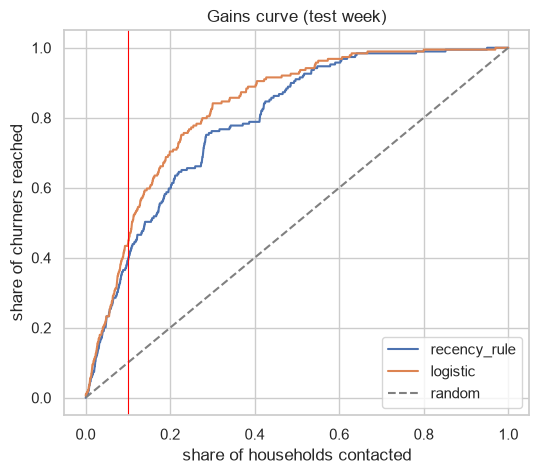

In [16]:
from src.config import FINAL_MODEL

# Gains curve: if we contact the top x% of households by risk, what share of all churners do we reach?
y = test_scores["churn"].to_numpy()
share_contacted = np.arange(1, len(y) + 1) / len(y)
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["recency_rule", FINAL_MODEL]:
    order = np.argsort(-test_scores[f"score_{name}"].to_numpy(), kind="stable")
    ax.plot(share_contacted, np.cumsum(y[order]) / y.sum(), label=name)
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="random")
ax.axvline(0.10, c="red", lw=0.8)
ax.set(title="Gains curve (test week)", xlabel="share of households contacted", ylabel="share of churners reached")
ax.legend()
fig.savefig(FIGURES_DIR / "gains_curve.png", dpi=120, bbox_inches="tight")
plt.show()

In [17]:
from sklearn.metrics import confusion_matrix

# Turn the ranking into a decision: send a coupon to the top 10%
k = int(len(y) * 0.10)
selected = np.zeros(len(y), dtype=int)
selected[np.argsort(-test_scores[f"score_{FINAL_MODEL}"].to_numpy(), kind="stable")[:k]] = 1
pd.DataFrame(confusion_matrix(y, selected), index=["did not churn", "churned"], columns=["no coupon", "coupon (top 10%)"])

,no coupon,coupon (top 10%)
did not churn,1978,149
churned,107,82


## Conclusions
* With the same budget, the model puts about **4.3x more** would-be churners in the top 10% than random targeting,
  and more than the "longest silence first" rule (82 vs 74 churners in the top 10%, PR-AUC 0.33 vs 0.27 on test).
* Logistic regression and random forest are tied, so we keep **logistic regression**: simpler, and easy to explain.
* Demographics add nothing. Most of the signal is in **how often and how recently** a household buys (notebook 03).